# Initial Exploratory Data Analysis

## Project: Predicting Successful NFL Third Down Conversions

This project examins NFLverse play-by-play data from the 2023-2026 seasons. The goal is to identify factors associated with successful third down conversions, including yards to go, field position, quarter, score differential, play time

**Data Source:** [NFLverse Play-by-Play Data](https://github.com/nflverse/nflverse-data/release/tag/pbp)

In [52]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


url_2023 = ("https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2023.parquet")
url_2024 = ("https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2024.parquet")
url_2025 = ("https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2025.parquet")
url_2026 = ("https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2026.parquet")

pbp_2023 = pd.read_parquet(url_2023)
pbp_2024 = pd.read_parquet(url_2024)
pbp_2025 = pd.read_parquet(url_2025)
pbp_2026 = pd.read_parquet(url_2026)

pbp = pd.concat([pbp_2023, pbp_2024, pbp_2025, pbp_2026], ignore_index=True)

pbp.head(5)

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,None,None,None,...,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,39.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,55.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0.0,1.0,-0.336103,NaN,NaN,NaN,NaN,NaN,0.515058,-51.505846
3,77.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0.0,1.0,0.703308,0.340652,3.328642,1.0,0.996628,0.583928,0.661106,33.889407
4,102.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0.0,1.0,0.469799,NaN,NaN,NaN,NaN,NaN,0.196065,-19.606467


In [3]:
print(f"Total: {pbp.shape[0]:,} rows, {pbp.shape[1]:,} columns\n")
print(f"Dataset: {pbp.shape[0]:,} plays from 2023-2026 seasons\n")
pbp["season"].value_counts().sort_index()

Total: 159,083 rows, 372 columns

Dataset: 159,083 plays from 2023-2026 seasons



,count
season,
2023,49665
2024,49492
2025,48771
2026,11155


In [4]:
pbp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159083 entries, 0 to 159082
Columns: 372 entries, play_id to pass_oe
dtypes: float64(200), int32(7), object(165)
memory usage: 447.3+ MB


In [5]:
pbp.describe()

,play_id,week,yardline_100,quarter_seconds_remaining,half_seconds_remaining,game_seconds_remaining,quarter_end,drive,sp,qtr,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
count,159083.000000,159083.000000,147738.000000,159066.000000,159066.000000,159066.000000,159083.000000,157259.000000,159083.000000,159083.000000,...,159083.000000,159083.000000,157245.000000,53814.000000,53814.000000,53814.000000,53814.000000,53814.000000,121185.000000,117700.000000
mean,2187.958537,9.431712,47.753056,408.808073,802.957672,1703.987433,0.017639,11.323733,0.075457,2.566830,...,0.085892,0.506597,0.007024,0.733477,5.527574,3.701862,0.775861,0.578954,0.628832,-1.417403
std,1274.732099,5.732873,23.937885,283.028255,561.100648,1058.211008,0.131634,6.593655,0.264129,1.128871,...,0.280206,0.499958,1.248386,0.528259,2.563305,2.629044,0.254137,0.357012,0.241039,42.376622
min,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,...,0.000000,0.000000,-12.689102,-3.181688,0.442673,0.000000,0.026981,0.004220,0.013008,-99.538189
25%,1093.000000,4.000000,30.000000,143.000000,273.000000,782.000000,0.000000,6.000000,0.000000,2.000000,...,0.000000,0.000000,-0.557777,0.325687,3.756694,2.000000,0.555868,0.242625,0.456025,-42.567039
50%,2167.000000,9.000000,49.000000,388.000000,784.000000,1800.000000,0.000000,11.000000,0.000000,2.000000,...,0.000000,1.000000,0.000000,0.608810,4.622212,3.000000,0.983203,0.474926,0.601361,3.846475
75%,3265.000000,14.000000,68.000000,654.000000,1285.000000,2589.000000,0.000000,17.000000,0.000000,4.000000,...,0.000000,1.000000,0.532150,1.007325,6.924195,5.000000,1.000000,0.999332,0.859478,32.902151
max,5519.000000,22.000000,99.000000,900.000000,1800.000000,3600.000000,1.000000,34.000000,1.000000,5.000000,...,1.000000,1.000000,8.882384,9.585749,23.952005,36.000000,1.000000,1.000000,0.997794,97.848164


In [6]:
pbp.columns.tolist()

['play_id',
 'game_id',
 'old_game_id',
 'home_team',
 'away_team',
 'season_type',
 'week',
 'posteam',
 'posteam_type',
 'defteam',
 'side_of_field',
 'yardline_100',
 'game_date',
 'quarter_seconds_remaining',
 'half_seconds_remaining',
 'game_seconds_remaining',
 'game_half',
 'quarter_end',
 'drive',
 'sp',
 'qtr',
 'down',
 'goal_to_go',
 'time',
 'yrdln',
 'ydstogo',
 'ydsnet',
 'desc',
 'play_type',
 'yards_gained',
 'shotgun',
 'no_huddle',
 'qb_dropback',
 'qb_kneel',
 'qb_spike',
 'qb_scramble',
 'pass_length',
 'pass_location',
 'air_yards',
 'yards_after_catch',
 'run_location',
 'run_gap',
 'field_goal_result',
 'kick_distance',
 'extra_point_result',
 'two_point_conv_result',
 'home_timeouts_remaining',
 'away_timeouts_remaining',
 'timeout',
 'timeout_team',
 'td_team',
 'td_player_name',
 'td_player_id',
 'posteam_timeouts_remaining',
 'defteam_timeouts_remaining',
 'total_home_score',
 'total_away_score',
 'posteam_score',
 'defteam_score',
 'score_differential',
 'po

In [7]:
#Looking for Missing Values
pbp.isnull().sum()

,0
play_id,0
game_id,0
old_game_id,0
home_team,0
away_team,0
...,...
xyac_median_yardage,105269
xyac_success,105269
xyac_fd,105269
xpass,37898


In [8]:
# Checking for Duplicate Values
print(f"Number of Duplicate Values: {pbp.duplicated().sum()}")

Number of Duplicate Values: 0


In [10]:
# Creating a new dataframe of only 3rd Down Plays
third_down = pbp[pbp["down"] == 3].copy()

print(f"Dataset: {third_down.shape[0]:,} third down plays from 2023-2026 seasons\n")

Dataset: 25,895 third down plays from 2023-2026 seasons



In [11]:
# Reviewing the types of third down plays
third_down['play_type'].value_counts(dropna=False)

,count
play_type,
pass,17502
run,5861
no_play,2207
qb_kneel,195
field_goal,104
qb_spike,26


In [12]:
# Reviewing the target variable
third_down['third_down_converted'].value_counts(dropna=False)

,count
third_down_converted,
0.0,16582
1.0,9272
NaN,41


In [14]:
# Revieing regular season vs playoffs
third_down['season_type'].value_counts(dropna=False)

,count
season_type,
REG,24817
POST,1078


In [15]:
# Keeping regular season third down attempts. This removes QB kneels, no_play, field goal attempts that were not intended to convert the third down.
third_down_analysis = third_down[
    (third_down['season_type'] == 'REG') &
    (third_down['play_type'].isin (['run','pass'])) &
    (third_down['third_down_converted'].notna())
].copy()

print(f"Dataset: {third_down_analysis.shape[0]:,} third down plays from 2023-2026 seasons\n")

Dataset: 22,366 third down plays from 2023-2026 seasons



In [18]:
analysis_columns = [
    "game_id",
    "play_id",
    "season",
    "week",
    "posteam",
    "defteam",
    "qtr",
    "game_seconds_remaining",
    "yardline_100",
    "ydstogo",
    "play_type",
    "third_down_converted",
    "posteam_timeouts_remaining",
    "defteam_timeouts_remaining",
    "score_differential",
    "shotgun"
]
eda_df = third_down_analysis[analysis_columns].copy()
eda_df.shape

(22366, 16)

In [20]:
# Looking for missing values in the selected analysis variables

missing_values = pd.DataFrame({
    "missing_count": eda_df.isna().sum(),
    "missing_percentage": eda_df.isna().mean() * 100
})

missing_values.sort_values(by="missing_percentage", ascending=False)
missing_values

,missing_count,missing_percentage
game_id,0,0.0
play_id,0,0.0
season,0,0.0
week,0,0.0
posteam,0,0.0
defteam,0,0.0
qtr,0,0.0
game_seconds_remaining,0,0.0
yardline_100,0,0.0
ydstogo,0,0.0


In [24]:
print("Complete Duplicate Rows:", eda_df.duplicated().sum())
print("Duplicate Rows by Play ID:", eda_df.duplicated(subset=["game_id", "play_id"]).sum())

Complete Duplicate Rows: 0
Duplicate Rows by Play ID: 0


In [31]:
conversion_summary = (eda_df["third_down_converted"].value_counts().reindex([0, 1], fill_value=0).rename_axis("conversion").reset_index(name="count"))

# Adding Descriptive Labels
conversion_summary["outcome"] = conversion_summary["conversion"].map({0: "Failed", 1: "Successful"})

# Calculating the proportion and percentage of third down plays
conversion_summary["rate"] = (conversion_summary["count"] / conversion_summary["count"].sum())

conversion_summary["rate_percentage"] = (conversion_summary["rate"] * 100).round(2).astype(str) + "%"

# Renaming Column Names to be more descriptive
conversion_summary = conversion_summary[["outcome", "count", "rate_percentage"]].rename(columns={
    "outcome": "Conversion Outcome",
    "count": "Number of Plays",
    "rate_percentage": "Percentage of Plays"
})

print(conversion_summary)


  Conversion Outcome  Number of Plays Percentage of Plays
0             Failed            13506              60.39%
1         Successful             8860              39.61%


In [43]:
# Comparing Conversion Rates by Seasons
conversion_by_season = (eda_df.groupby("season", as_index=False)
.agg(
    number_of_plays = ("third_down_converted", "count"),
    successful_conversions = ("third_down_converted", "sum"),
    conversion_rate = ("third_down_converted", "mean")
))

# Converting Rate to Percentage
conversion_by_season["conversion_rate"] = (conversion_by_season["conversion_rate"] * 100).round(2).astype(str) + "%"

# Renaming Columns
conversion_by_season = conversion_by_season.rename(columns={
    "season": "Season",
    "number_of_plays": "Number of Plays",
    "successful_conversions": "Successful Conversions",
    "conversion_rate": "Conversion Rate (%)"
})

conversion_by_season

,Season,Number of Plays,Successful Conversions,Conversion Rate (%)
0,2023,7140,2788.0,39.05%
1,2024,6828,2728.0,39.95%
2,2025,6801,2710.0,39.85%
3,2026,1597,634.0,39.7%


In [50]:
conversion_by_play_type = ( eda_df.groupby("play_type", as_index=False)["third_down_converted"]
.agg(["count", "mean"])
)
conversion_by_play_type["conversion_rate_percent"] = (conversion_by_play_type["mean"]* 100).round(2).astype(str) + "%"

# Renaming Columns
conversion_by_play_type = conversion_by_play_type[["play_type", "count", "conversion_rate_percent"]].rename(columns={
    "play_type": "Play Type",
    "count": "Number of Plays",
    "conversion_rate_percent": "Conversion Rate(%)"
})

conversion_by_play_type

,Play Type,Number of Plays,Conversion Rate(%)
0,pass,16777,35.06%
1,run,5589,53.28%


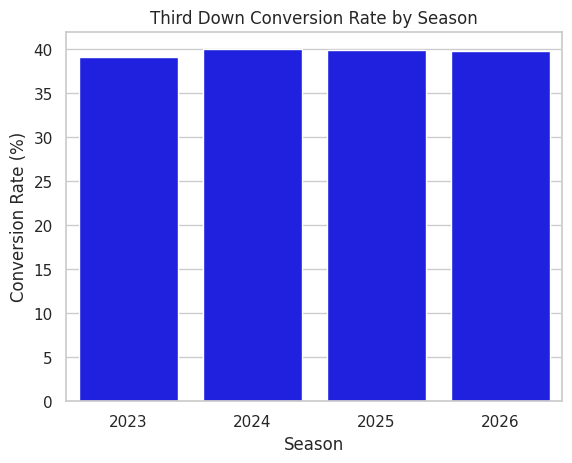

In [54]:
sns.set_theme(style="whitegrid")

season_plot = (eda_df.groupby("season", as_index=False)["third_down_converted"].mean())

season_plot["conversion_rate"] = (season_plot["third_down_converted"]* 100)

sns.barplot(
    data=season_plot,
    x="season",
    y="conversion_rate",
    color="blue"
)

plt.title("Third Down Conversion Rate by Season")
plt.xlabel("Season")
plt.ylabel("Conversion Rate (%)")
plt.show()